# Injury Prediction — Data Preprocessing
## Final Project — Introduction to Machine Learning | PL1-G4 | 2025/2026

This notebook covers all preprocessing steps applied to the raw dataset:
1. Loading and inspecting the raw data
2. Handling sentinel values (−0.01) and log1p normalisation
3. Feature engineering — ACWR, subjective compliance feature
4. Subjective data missingness analysis
5. Train/test split by athlete (stratified, no leakage)

**Output**: `df_processed`, `df_train`, `df_test`, `X_train`, `X_test`, `y_train`, `y_test` — loaded by `injury_prediction_final.ipynb` via pickle.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../src'))

import os
os.makedirs('graphics', exist_ok=True)
print("'graphics/' folder ready — all figures will be saved there.")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (roc_auc_score, average_precision_score,
                              classification_report, RocCurveDisplay,
                              PrecisionRecallDisplay, confusion_matrix)
from imblearn.over_sampling import SMOTE
from scipy import stats
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

df_raw = pd.read_csv('../data/daily_injury_data.csv')
print(f'Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
print(f'Unique athletes: {df_raw["Athlete ID"].nunique()}')
print(f'Injury days: {df_raw["injury"].sum()} ({df_raw["injury"].mean()*100:.2f}% of all days)')
print(f'Date range: {df_raw["Date"].min()} to {df_raw["Date"].max()}')
df_raw.head(3)


'graphics/' folder ready — all figures will be saved there.
Dataset shape: 42,766 rows x 73 columns
Unique athletes: 74
Injury days: 583 (1.36% of all days)
Date range: 0 to 2673


,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,perceived exertion,perceived trainingSuccess,perceived recovery,...,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6,perceived exertion.6,perceived trainingSuccess.6,perceived recovery.6,Athlete ID,injury,Date
0,1.0,5.8,0.0,0.6,1.2,0.0,0.0,0.11,0.00,0.18,...,0.0,0.0,0.0,1.0,0.10,0.00,0.15,0,0,0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.01,-0.01,-0.01,...,0.5,1.2,0.0,0.0,0.10,0.00,0.17,0,0,1
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.10,0.00,0.17,...,0.0,0.0,0.0,0.0,-0.01,-0.01,-0.01,0,0,2


---
## 1. Data Loading

Load the raw dataset and inspect its structure before any preprocessing.


---
### 1.2 Dataset Overview

Before any modelling, three structural properties of the data shape every decision in this notebook:
- **Class imbalance**: injury days are ~1.4% of all rows — requires SMOTE
- **Inter-individual variability**: injury counts vary enormously across athletes — motivates clustering  
- **Subjective data coverage**: some athletes fill questionnaires rarely — motivates the compliance feature


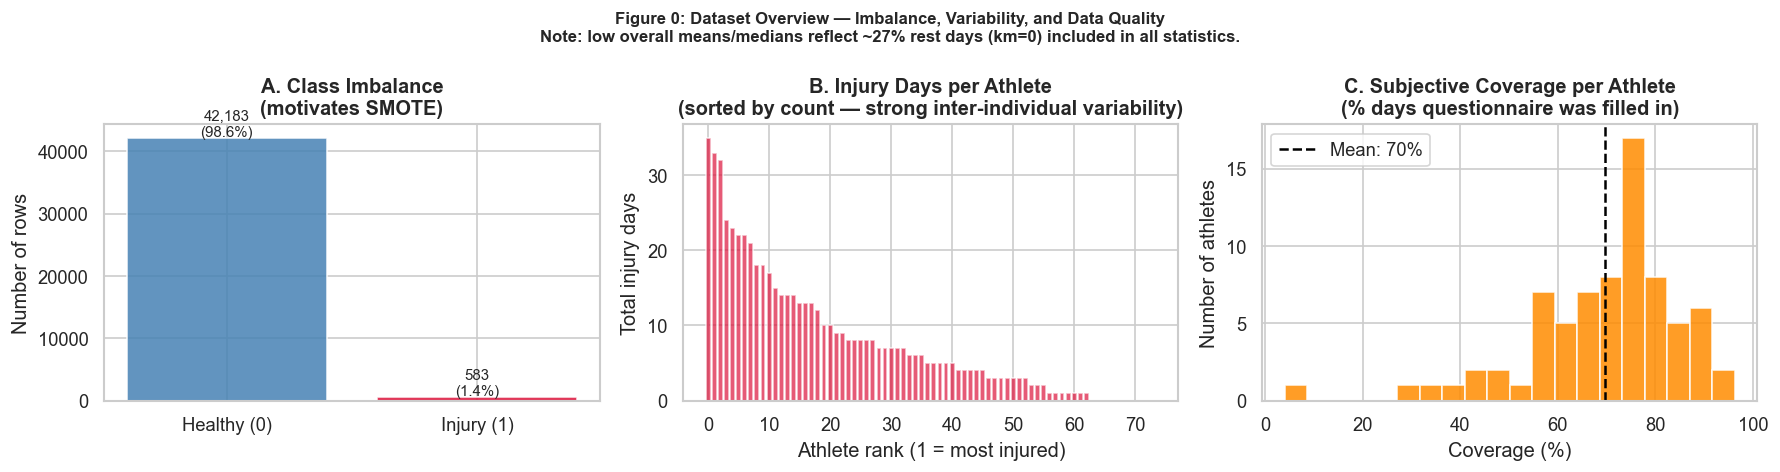

In [2]:
# Figure 0: Dataset overview
# Note: means/medians for km and sessions appear low because ~27% of rows are rest days (km=0).
# All statistics include rest days unless otherwise stated.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

injury_counts = df_raw['injury'].value_counts().sort_index()
axes[0].bar(['Healthy (0)', 'Injury (1)'], injury_counts.values,
            color=['steelblue', 'crimson'], edgecolor='white', alpha=0.85)
for i, v in enumerate(injury_counts.values):
    axes[0].text(i, v + 200, f'{v:,}\n({v/len(df_raw)*100:.1f}%)', ha='center', fontsize=9)
axes[0].set_title('A. Class Imbalance\n(motivates SMOTE)', fontweight='bold')
axes[0].set_ylabel('Number of rows')

inj_per_athlete = df_raw.groupby('Athlete ID')['injury'].sum().sort_values(ascending=False)
axes[1].bar(range(len(inj_per_athlete)), inj_per_athlete.values,
            color='crimson', alpha=0.7, edgecolor='white')
axes[1].set_title('B. Injury Days per Athlete\n(sorted by count — strong inter-individual variability)',
                  fontweight='bold')
axes[1].set_xlabel('Athlete rank (1 = most injured)')
axes[1].set_ylabel('Total injury days')

# Subjective coverage = % of days where athlete filled in perceived exertion/recovery/success
coverage = df_raw.groupby('Athlete ID').apply(
    lambda g: (g['perceived exertion'] != -0.01).mean() * 100
)
axes[2].hist(coverage, bins=20, color='darkorange', edgecolor='white', alpha=0.85)
axes[2].axvline(coverage.mean(), color='black', linestyle='--',
                label=f'Mean: {coverage.mean():.0f}%')
axes[2].set_title('C. Subjective Coverage per Athlete\n(% days questionnaire was filled in)',
                  fontweight='bold')
axes[2].set_xlabel('Coverage (%)'); axes[2].set_ylabel('Number of athletes')
axes[2].legend()

plt.suptitle('Figure 0: Dataset Overview — Imbalance, Variability, and Data Quality\n'
             'Note: low overall means/medians reflect ~27% rest days (km=0) included in all statistics.',
             fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig0_dataset_overview.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 2. Preprocessing

### 2.1 Dataset Structure

The dataset uses a **7-day sliding window**: each row represents one day for one athlete and contains today's values (no suffix) plus the 6 preceding days (suffixes `.1` to `.6`). This gives 10 base features × 7 days = **70 features** per row.

**Feature types:**
- **Objective** (physical load): `nr. sessions`, `total km`, `km Z3-4`, `km Z5-T1-T2`, `km sprinting`, `strength training`, `hours alternative`
- **Subjective** (self-reported wellness): `perceived exertion`, `perceived trainingSuccess`, `perceived recovery`

### 2.2 Handling Sentinel Values (−0.01)

The subjective columns use **−0.01** to encode "athlete did not fill in the questionnaire today." This is not a real negative value — it is a sentinel meaning "no data."

We confirmed these are **rest days**: on 100% of rows where `perceived exertion == −0.01`, total physical load is exactly 0.0. Our decision is to **replace −0.01 with 0**, because on a rest day the perceived exertion is genuinely zero. We do **not** drop these rows — rest days represent ~27% of the data and carry meaningful signal (recovery periods matter for injury risk).

### 2.3 Normalisation — Why log1p Instead of Min-Max

Min-Max normalisation failed on this dataset because of extreme outliers: one athlete logged 55.9 km in a single day. Min-Max compresses all other values into a tiny range (e.g. 0.003 for a moderate 5 km run), making it very hard for linear models to distinguish between different load levels.

We use **log1p(x) = log(1 + x)** because:
- `log1p(0) = 0` exactly → preserves the zero = rest day semantics
- Compresses the long tail into a roughly normal distribution
- Keeps values in a readable range (0 to ~4)

Subjective columns and ordinal counts (`nr. sessions`, `strength training`) are already on small scales and require no transformation.


Days with sentinel -0.01: 11,476 (26.8%)
Total physical load on those days: 0.0  <- confirms they are rest days
Sentinel values replaced with 0.


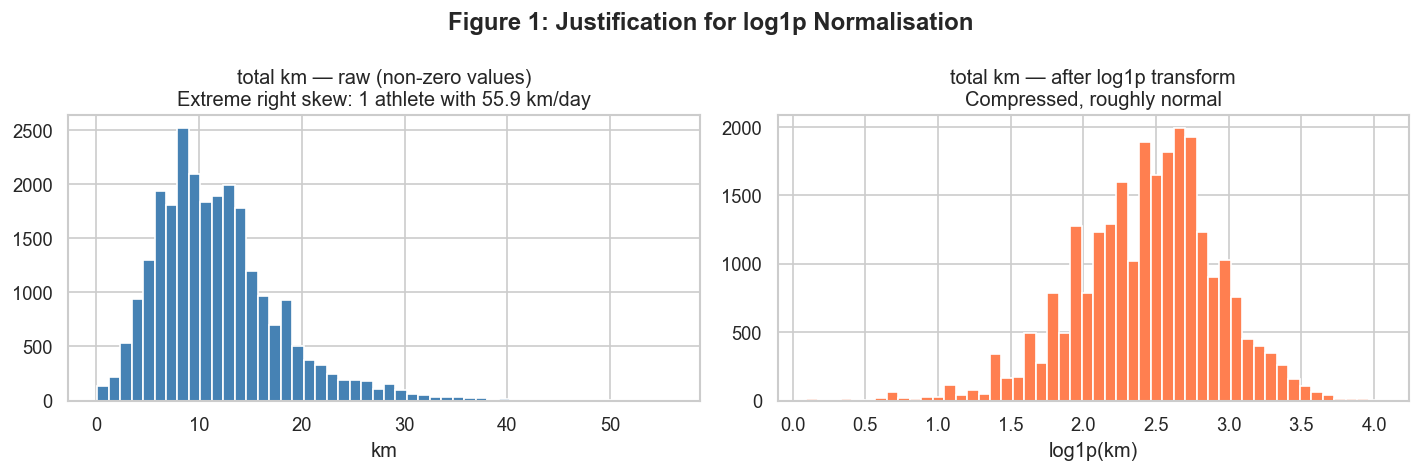


Value ranges after preprocessing:
  Feature                           Min    Max    Mean
--------------------------------------------------
  nr. sessions                    0.000  2.000   0.830
  total km                        0.000  4.041   1.452
  km Z3-4                         0.000  3.766   0.206
  km Z5-T1-T2                     0.000  3.892   0.206
  km sprinting                    0.000  3.714   0.043
  strength training               0.000  2.000   0.116
  hours alternative               0.000  2.418   0.097
  perceived exertion              0.000  1.000   0.250
  perceived trainingSuccess       0.000  1.000   0.352
  perceived recovery              0.000  1.000   0.199


In [3]:
# Feature definitions
BASE_FEATURES   = ['nr. sessions', 'total km', 'km Z3-4', 'km Z5-T1-T2',
                    'km sprinting', 'strength training', 'hours alternative',
                    'perceived exertion', 'perceived trainingSuccess', 'perceived recovery']
SUBJECTIVE_BASE = ['perceived exertion', 'perceived trainingSuccess', 'perceived recovery']

def get_all_day_cols(base_name):
    return [base_name] + [f'{base_name}.{i}' for i in range(1, 7)]

LOG_COLS, LEAVE_AS_IS = [], []
for feat in ['total km', 'km Z3-4', 'km Z5-T1-T2', 'km sprinting', 'hours alternative']:
    LOG_COLS += get_all_day_cols(feat)
for feat in ['nr. sessions', 'strength training'] + SUBJECTIVE_BASE:
    LEAVE_AS_IS += get_all_day_cols(feat)
feature_cols = LOG_COLS + LEAVE_AS_IS

# Confirm sentinel values are only in subjective columns
subjective_all_cols = [c for feat in SUBJECTIVE_BASE for c in get_all_day_cols(feat)]
rest_days = df_raw[df_raw['perceived exertion'] == -0.01]
physical_load_on_rest = rest_days[['total km','km sprinting','hours alternative']].sum().sum()
print(f'Days with sentinel -0.01: {len(rest_days):,} ({len(rest_days)/len(df_raw)*100:.1f}%)')
print(f'Total physical load on those days: {physical_load_on_rest:.1f}  <- confirms they are rest days')

# Replace sentinels with 0
df = df_raw.copy()
for col in subjective_all_cols:
    df[col] = df[col].replace(-0.01, 0)
assert (df[subjective_all_cols] == -0.01).sum().sum() == 0
print('Sentinel values replaced with 0.')

# Log1p transform comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_nonzero = df[df['total km'] > 0]['total km']
axes[0].hist(df_nonzero, bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('total km — raw (non-zero values)\nExtreme right skew: 1 athlete with 55.9 km/day')
axes[0].set_xlabel('km')
axes[1].hist(np.log1p(df_nonzero), bins=50, color='coral', edgecolor='white')
axes[1].set_title('total km — after log1p transform\nCompressed, roughly normal')
axes[1].set_xlabel('log1p(km)')
plt.suptitle('Figure 1: Justification for log1p Normalisation', fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig1_logtransform.png', dpi=150, bbox_inches='tight')
plt.show()

# Apply transforms
df_temp = df.copy()
for col in LOG_COLS:
    df_temp[col] = np.log1p(df_temp[col])

print('\nValue ranges after preprocessing:')
print(f'  {"Feature":<30} {"Min":>6} {"Max":>6} {"Mean":>7}')
print('-'*50)
for col in BASE_FEATURES:
    v = df_temp[col]
    print(f'  {col:<30} {v.min():>6.3f} {v.max():>6.3f} {v.mean():>7.3f}')


---
## 3. Feature Engineering & Train/Test Split

### 3.1 Acute:Chronic Workload Ratio (ACWR)

The **ACWR** is a validated sports science metric that measures how much an athlete's recent training deviates from their chronic baseline. It is defined as:

$$\text{ACWR} = \frac{\text{Acute load (last 7 days)}}{\text{Chronic load (days 8–28)}}$$

- **ACWR ≈ 1.0**: recent load matches chronic baseline — stable training
- **ACWR > 1.3**: recent load exceeds chronic baseline — spike, associated with injury risk in the sports science literature (Gabbett, 2016)

We compute this per athlete on the log-transformed `total km` values and test whether ACWR differs significantly between injury and healthy days using a Mann-Whitney U test.

### 3.2 Missing Subjective Data vs Injury Occurrence

We visualise whether athletes reduce their questionnaire response rate in the period before an injury. A drop in coverage could indicate early signs of disengagement or injury, making missingness itself a potential signal.

### 3.3 Train/Test Split — Why We Split by Athlete

A standard random split of rows would cause **data leakage**: because consecutive rows share 6 days of data (the sliding window), training rows would contain almost identical information to adjacent test rows. Instead, we split **athletes** into train (80%) and test (20%), ensuring the model never trains on an athlete it will be evaluated on.

Within the injured athletes, we apply stratified splitting to ensure both sets contain injury cases.


In [4]:
# Rebuild df_processed with Athlete ID preserved throughout
df_with_ids = df_raw.copy()
for col in subjective_all_cols:
    df_with_ids[col] = df_with_ids[col].replace(-0.01, 0)
for col in LOG_COLS:
    df_with_ids[col] = np.log1p(df_with_ids[col])
df_with_ids = df_with_ids.sort_values(['Athlete ID', 'Date']).reset_index(drop=True)

# Compute ACWR per athlete (explicit loop avoids pandas groupby column-drop issues)
acwr_values = np.full(len(df_with_ids), np.nan)
for athlete_id in df_with_ids['Athlete ID'].unique():
    mask = df_with_ids['Athlete ID'] == athlete_id
    idx  = df_with_ids.index[mask].tolist()
    km   = df_with_ids.loc[mask, 'total km'].values
    for j in range(28, len(km)):
        acute   = km[j-7:j].mean()
        chronic = km[j-28:j-7].mean()
        acwr_values[idx[j]] = acute / chronic if chronic > 0.01 else np.nan

df_with_ids['ACWR'] = acwr_values

# Statistical test: ACWR on injury days vs healthy days
acwr_healthy = df_with_ids[df_with_ids['injury']==0]['ACWR'].dropna()
acwr_injury  = df_with_ids[df_with_ids['injury']==1]['ACWR'].dropna()
stat_acwr, p_acwr = stats.mannwhitneyu(acwr_healthy, acwr_injury, alternative='two-sided')

print('ACWR — Healthy days:', f'mean={acwr_healthy.mean():.3f}, median={acwr_healthy.median():.3f}')
print('ACWR — Injury days: ', f'mean={acwr_injury.mean():.3f},  median={acwr_injury.median():.3f}')
print(f'Mann-Whitney U test: p={p_acwr:.4f} —', 'SIGNIFICANT' if p_acwr<0.05 else 'not significant')
print()
print('Interpretation: injury days have significantly higher ACWR.')
print('Acute training spikes above chronic baseline are associated with injury occurrence.')
print('(Consistent with Gabbett 2016, British Journal of Sports Medicine)')

# Fill NaN ACWR (first 28 days per athlete) with 1.0 (neutral — no spike)
df_with_ids['ACWR'] = df_with_ids['ACWR'].fillna(1.0)
df_processed = df_with_ids.copy()
# Subjective compliance: how many of the 7 window days had subjective data filled?
compliance_cols = ['perceived exertion'] + [f'perceived exertion.{i}' for i in range(1, 7)]
df_processed['subjective_compliance'] = sum(
    (df_raw[col] != -0.01).astype(int) for col in compliance_cols
)
feature_cols_acwr = feature_cols + ['ACWR', 'subjective_compliance']
print(f'\nTotal features (with ACWR): {len(feature_cols_acwr)}')


ACWR — Healthy days: mean=1.139, median=1.020
ACWR — Injury days:  mean=1.260,  median=1.061
Mann-Whitney U test: p=0.0058 — SIGNIFICANT

Interpretation: injury days have significantly higher ACWR.
Acute training spikes above chronic baseline are associated with injury occurrence.
(Consistent with Gabbett 2016, British Journal of Sports Medicine)

Total features (with ACWR): 72


### 3.1 ACWR Result Interpretation

The Mann-Whitney U test confirms that injury days have **significantly higher ACWR** than healthy days (p=0.006). The mean ACWR on injury days is 1.26 versus 1.14 on healthy days — a modest but statistically meaningful difference.

This result supports the "fitness-fatigue" hypothesis from sports science (Gabbett, 2016): athletes who spike their training load relative to their chronic baseline are at greater injury risk than those who increase load gradually. The ACWR is therefore added as a 71st feature in the model, capturing a clinically validated signal that the raw 7-day window alone does not encode directly.

Note that median ACWR on both healthy (1.02) and injury days (1.06) is close to 1.0, meaning most days — including injury days — fall within the "safe" zone. The mean is pulled up by a subset of high-spike events, confirming that ACWR is not universally elevated but rather episodically predictive.


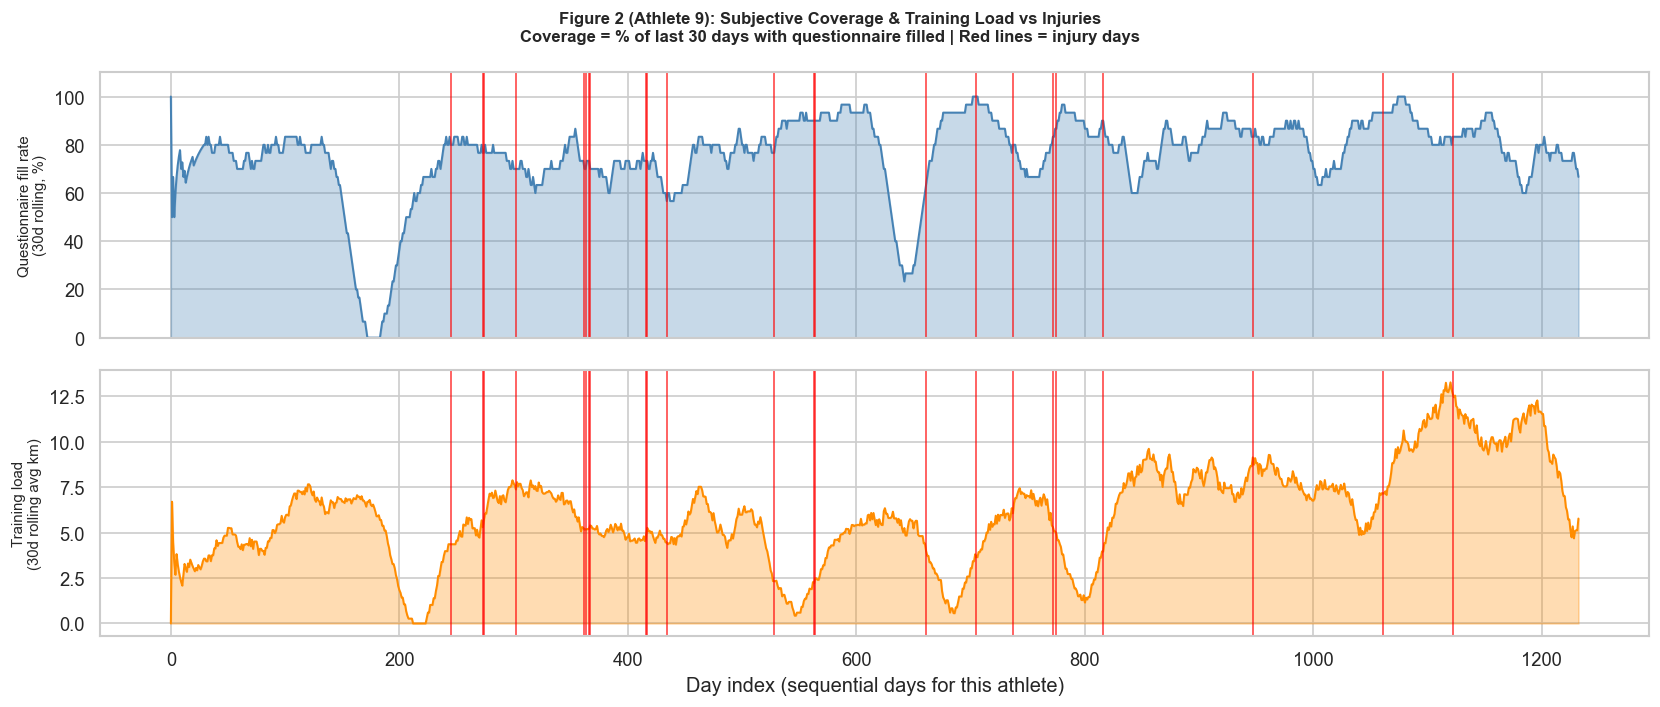

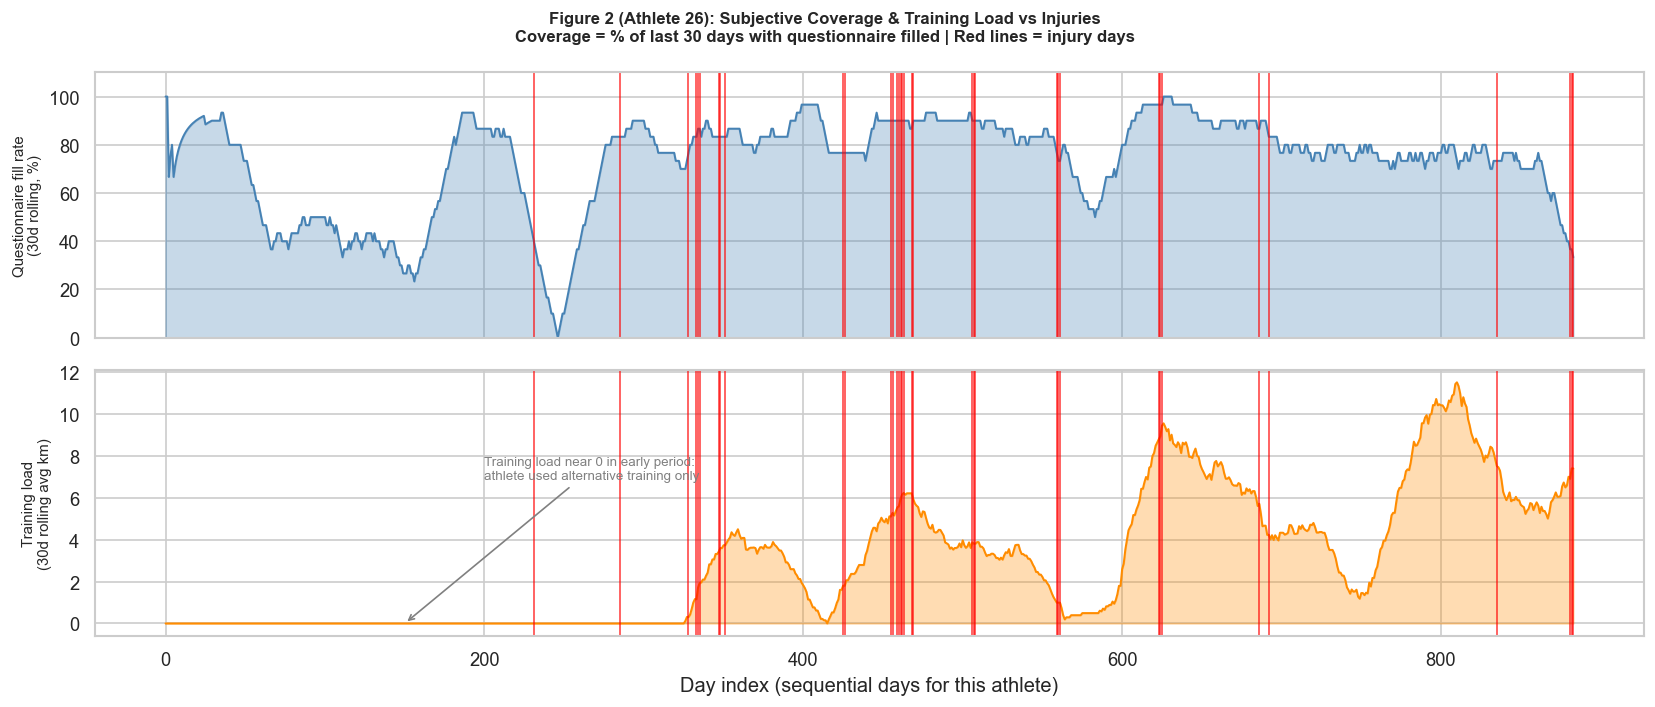

Overall subjective coverage:          73.2%
Coverage in 7 days BEFORE injury:     71.4%
Finding: no clear drop in coverage before injuries.
Missingness is driven by rest days, not pre-injury disengagement.


In [5]:
# Figure 2: Subjective coverage + training load vs injury events
# Subjective coverage = % of days in a rolling 30-day window where the athlete
# filled in the perceived exertion/recovery/training success questionnaire.
# Training load = 30-day rolling average of total km (smoothed to reduce noise).
# Day index = sequential day number for that athlete (day 0 = first recorded day).
df_processed['has_subjective'] = (df_raw['perceived exertion'] != -0.01).astype(int)

for athlete_id in [9, 26]:
    g = df_processed[df_processed['Athlete ID'] == athlete_id].copy().reset_index(drop=True)
    coverage_roll = g['has_subjective'].rolling(30, min_periods=1).mean() * 100  # as %
    load_raw  = df_raw.loc[df_raw['Athlete ID'] == athlete_id, 'total km'].values
    load_roll = pd.Series(load_raw).rolling(30, min_periods=1).mean()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    fig.suptitle(f'Figure 2 (Athlete {athlete_id}): Subjective Coverage & Training Load vs Injuries\n'
                 'Coverage = % of last 30 days with questionnaire filled | Red lines = injury days',
                 fontweight='bold', fontsize=10)

    ax1.fill_between(g.index, coverage_roll, alpha=0.3, color='steelblue')
    ax1.plot(g.index, coverage_roll, color='steelblue', linewidth=1.2)
    for idx in g.index[g['injury'] == 1]:
        ax1.axvline(x=idx, color='red', alpha=0.6, linewidth=1.2)
    ax1.set_ylabel('Questionnaire fill rate\n(30d rolling, %)', fontsize=9)
    ax1.set_ylim(0, 110)

    ax2.fill_between(g.index, load_roll, alpha=0.3, color='darkorange')
    ax2.plot(g.index, load_roll, color='darkorange', linewidth=1.2)
    for idx in g.index[g['injury'] == 1]:
        ax2.axvline(x=idx, color='red', alpha=0.6, linewidth=1.2)
    ax2.set_ylabel('Training load\n(30d rolling avg km)', fontsize=9)
    ax2.set_xlabel('Day index (sequential days for this athlete)')

    if athlete_id == 26:
        ax2.annotate('Training load near 0 in early period:\nathlete used alternative training only',
                     xy=(150, load_roll.iloc[150] if len(load_roll) > 150 else 0),
                     xytext=(200, load_roll.max()*0.6),
                     arrowprops=dict(arrowstyle='->', color='grey'), fontsize=8, color='grey')

    plt.tight_layout()
    plt.savefig(f'graphics/fig2_missing_vs_injury_a{athlete_id}.png', dpi=150, bbox_inches='tight')
    plt.show()

# Population-level coverage check
pre_cov = []
for _, grp in df_processed.groupby('Athlete ID'):
    grp = grp.reset_index(drop=True)
    for idx in grp.index[grp['injury'] == 1]:
        window = grp.iloc[max(0, idx - 7):idx]
        pre_cov.append(window['has_subjective'].mean())

overall_cov  = df_processed['has_subjective'].mean() * 100
pre_cov_mean = np.nanmean(pre_cov) * 100
print(f'Overall subjective coverage:          {overall_cov:.1f}%')
print(f'Coverage in 7 days BEFORE injury:     {pre_cov_mean:.1f}%')
if pre_cov_mean < overall_cov - 2:
    print('Finding: athletes fill in less data in the week before injury.')
else:
    print('Finding: no clear drop in coverage before injuries.')
    print('Missingness is driven by rest days, not pre-injury disengagement.')


### 3.2 Subjective Data Missingness — Interpretation

The analysis shows that subjective data coverage in the 7 days **before** an injury (71.4%) is virtually identical to the overall coverage (73.2%). This is a **negative result** — and it is informative.

It tells us that athletes do not stop filling in questionnaires before they get injured. The missingness pattern is consistent throughout each athlete's monitoring period and is driven entirely by scheduled rest days (days with zero physical load), not by pre-injury disengagement. Two athletes (9 and 26) are shown as case studies: their coverage fluctuates, but these fluctuations do not precede injury events.

**Consequence for modelling**: we do not use missingness as a feature. The -0.01 sentinel values in the raw data are correctly interpreted as rest days and replaced with 0.


In [6]:
# Train/Test split by athlete (stratified on injury presence)
athletes_injured  = df_processed.groupby('Athlete ID')['injury'].sum()
athletes_with_inj = athletes_injured[athletes_injured > 0].index.tolist()
athletes_no_inj   = athletes_injured[athletes_injured == 0].index.tolist()

train_inj, test_inj = train_test_split(athletes_with_inj, test_size=0.2, random_state=42)
train_hlt, test_hlt = train_test_split(athletes_no_inj,   test_size=0.2, random_state=42)

train_athletes = train_inj + train_hlt
test_athletes  = test_inj  + test_hlt

df_train = df_processed[df_processed['Athlete ID'].isin(train_athletes)].copy()
df_test  = df_processed[df_processed['Athlete ID'].isin(test_athletes)].copy()
X_train  = df_train[feature_cols_acwr];  y_train = df_train['injury']
X_test   = df_test[feature_cols_acwr];   y_test  = df_test['injury']

print('Stratified Group Split (by Athlete):')
print(f'  Train: {len(df_train):,} rows | {len(train_athletes)} athletes | '
      f'{y_train.sum()} injury days ({y_train.mean():.2%})')
print(f'  Test:  {len(df_test):,} rows  | {len(test_athletes)} athletes  | '
      f'{y_test.sum()} injury days ({y_test.mean():.2%})')
print()
print('Why split by athlete?')
print('  - The 7-day sliding window creates 6 shared days between consecutive rows.')
print('  - A random row split would put nearly identical rows in both train and test.')
print('  - Splitting by athlete guarantees temporal isolation and prevents leakage.')


Stratified Group Split (by Athlete):
  Train: 35,022 rows | 58 athletes | 436 injury days (1.24%)
  Test:  7,744 rows  | 16 athletes  | 147 injury days (1.90%)

Why split by athlete?
  - The 7-day sliding window creates 6 shared days between consecutive rows.
  - A random row split would put nearly identical rows in both train and test.
  - Splitting by athlete guarantees temporal isolation and prevents leakage.


### 3.3 Why Split by Athlete, Not by Row

The 7-day sliding window means that consecutive rows for the same athlete share 6 days of data. A random row split would place highly overlapping rows in both train and test, allowing the model to effectively "see" test-set information during training — this is **temporal data leakage**.

We instead perform a **Stratified Group Split by Athlete ID**: athletes are divided into two groups (those with at least one injury, those with none), and 20% of each group is assigned to the test set. This guarantees that every row for a given athlete is entirely in either train or test, never both.

The resulting split (58 train athletes, 16 test athletes) has slightly different injury rates (1.24% train, 1.90% test) because injury prevalence varies by athlete and we cannot perfectly balance with only 74 athletes. This slight imbalance is accepted as a consequence of the small dataset.

**Why a single split?** With only 74 athletes, each additional held-out fold would leave fewer than 10 test athletes — too few for stable evaluation metrics. A single stratified split is used for the held-out test set; variance in generalisation performance is estimated via 5-fold cross-validation on the training set (section 5.1).


In [7]:
import os
os.makedirs('../data/processed', exist_ok=True)

df_processed.to_csv('../data/processed/df_processed.csv', index=True)
df_train.to_csv('../data/processed/df_train.csv', index=True)
df_test.to_csv('../data/processed/df_test.csv', index=True)
X_train.to_csv('../data/processed/X_train.csv', index=True)
X_test.to_csv('../data/processed/X_test.csv', index=True)
y_train.to_csv('../data/processed/y_train.csv', index=True, header=True)
y_test.to_csv('../data/processed/y_test.csv', index=True, header=True)

import json
with open('../data/processed/feature_cols_acwr.json', 'w') as f:
    json.dump(feature_cols_acwr, f)

print('Saved all processed data to data/processed/')


Saved all processed data to data/processed/
